Partie 1 — Exploration des données
*****************************************

In [1]:
import pandas as pd
from pathlib import Path

In [2]:
file_path = Path("../data/raw/Online Retail.xlsx")

print("Fichier trouvé :", file_path.exists())
print("Chemin utilisé :", file_path.resolve())

Fichier trouvé : True
Chemin utilisé : C:\Users\user\Desktop\Retail-Sales-Analytics-BI\data\raw\Online Retail.xlsx


In [3]:
# Lire le fichier Excel en préservant les codes comme du texte
df = pd.read_excel(
    file_path,
    dtype={"InvoiceNo": str, "StockCode": str}
)

print("Données chargées avec succès !")

Données chargées avec succès !


Comprendre la structure du dataset
*************************************

In [4]:
#   Afficher les premières lignes
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
#   le nombre de lignes et de colonnes
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes : 541909
Nombre de colonnes : 8


In [6]:
#   Afficher les noms des colonnes
print("Noms des colonnes :", df.columns.tolist())

Noms des colonnes : ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [7]:
#   Vérifier les types de données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(1), str(3)
memory usage: 33.1+ MB


In [8]:
#   Afficher les statistiques descriptives
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Premier diagnostic de qualité
********************************

In [9]:
#   Valeurs manquantes
df.isna().sum().sort_values(ascending=False)

CustomerID     135080
Description      1454
StockCode           0
InvoiceNo           0
Quantity            0
InvoiceDate         0
UnitPrice           0
Country             0
dtype: int64

In [10]:
#   Lignes dupliquées
print("Lignes dupliquées :", df.duplicated().sum())

Lignes dupliquées : 5268


In [11]:
#   Quantités et prix
print("Quantités négatives :", (df["Quantity"] < 0).sum())
print("Prix négatifs :", (df["UnitPrice"] < 0).sum())

Quantités négatives : 10624
Prix négatifs : 2


In [12]:
#   Identifier les commandes annulées
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

cancelled = df[df["InvoiceNo"].str.startswith("C")]

print("Nombre de lignes d'annulation :", len(cancelled))
cancelled.head()

Nombre de lignes d'annulation : 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [13]:
#   Calculer les indicateurs de qualité
quality_report = pd.DataFrame({
    "Valeurs manquantes": df.isna().sum(),
    "Pourcentage manquant (%)": (
        df.isna().mean() * 100
    ).round(2),
    "Valeurs distinctes": df.nunique()
})

quality_report

,Valeurs manquantes,Pourcentage manquant (%),Valeurs distinctes
InvoiceNo,0,0.00,25900
StockCode,0,0.00,4070
Description,1454,0.27,4223
Quantity,0,0.00,722
InvoiceDate,0,0.00,23260
UnitPrice,0,0.00,1630
CustomerID,135080,24.93,4372
Country,0,0.00,38


In [14]:
#    Exporter les données en CSV
output_path = Path("../data/raw/online_retail.csv")

df.to_csv(output_path, index=False)

print("Fichier exporté :", output_path)
print("Fichier présent :", output_path.exists())

Fichier exporté : ..\data\raw\online_retail.csv
Fichier présent : True


Partie 2 — Nettoyage et transformation
*********************************************

In [15]:
#Étape 1 — Supprimer les doublons exacts
df_clean = df.copy()

print("Lignes avant :", len(df_clean))
print("Doublons exacts :", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Lignes après :", len(df_clean))

Lignes avant : 541909
Doublons exacts : 5268
Lignes après : 536641


In [16]:
#Étape 2 — Séparer les annulations
cancelled = df_clean[
    df_clean["InvoiceNo"].str.startswith("C", na=False)
].copy()

ventes = df_clean[
    ~df_clean["InvoiceNo"].str.startswith("C", na=False)
].copy()

print("Annulations :", len(cancelled))
print("Lignes restantes :", len(ventes))

Annulations : 9251
Lignes restantes : 527390


In [17]:
#Étape 3 — Écarter les quantités et prix invalides
print("Quantités négatives :", (ventes["Quantity"] < 0).sum())
print("Prix nuls ou négatifs :", (ventes["UnitPrice"] <= 0).sum())

ventes = ventes[
    (ventes["Quantity"] > 0) &
    (ventes["UnitPrice"] > 0)
].copy()

print("Lignes après filtrage :", len(ventes))

Quantités négatives : 1336
Prix nuls ou négatifs : 2512
Lignes après filtrage : 524878


In [18]:
#Étape 4 — Écarter les codes produit techniques

# Convertir les codes produit en texte
ventes["StockCode"] = ventes["StockCode"].astype("string").str.strip()

# Conserver les codes composés exactement de 5 chiffres
masque_produits = ventes["StockCode"].str.fullmatch(
    r"\d{5}",
    na=False
)

ventes = ventes[masque_produits].copy()

print("Lignes après filtrage :", len(ventes))

Lignes après filtrage : 472253


In [19]:
#Étape 5 — Traiter les clients et les descriptions manquants
print("Clients manquants :", ventes["CustomerID"].isna().sum())

ventes["CustomerID"] = ventes["CustomerID"].fillna(0)

print("Clients manquants après traitement :",
      ventes["CustomerID"].isna().sum())

Clients manquants : 113976
Clients manquants après traitement : 0


In [20]:
#Étape 6 — Normaliser les descriptions et calculer le montant
ventes["Description"] = (
    ventes["Description"]
    .str.strip()
    .str.upper()
)

ventes["montant"] = ventes["Quantity"] * ventes["UnitPrice"]

ventes[["InvoiceNo", "StockCode", "Description",
        "Quantity", "UnitPrice", "montant"]].head()

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,montant
1,536365,71053,WHITE METAL LANTERN,6,3.39,20.34
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,7.65,15.30
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,25.50
7,536366,22633,HAND WARMER UNION JACK,6,1.85,11.10
8,536366,22632,HAND WARMER RED POLKA DOT,6,1.85,11.10


In [22]:
#Étape 7 — Enregistrer les données nettoyées
from pathlib import Path

output_dir = Path("../data/clean")
output_dir.mkdir(parents=True, exist_ok=True)

ventes.to_csv(output_dir / "ventes.csv", index=False)
cancelled.to_csv(output_dir / "annulations.csv", index=False)

print("Ventes exportées :", len(ventes))
print("Annulations exportées :", len(cancelled))

Ventes exportées : 472253
Annulations exportées : 9251


In [23]:
#Vérifier les données nettoyées
print("Nombre de ventes :", len(ventes))
print("Nombre d'annulations :", len(cancelled))
print("Doublons restants :", ventes.duplicated().sum())
print("Quantités non positives :", (ventes["Quantity"] <= 0).sum())
print("Prix non positifs :", (ventes["UnitPrice"] <= 0).sum())
print("Clients manquants :", ventes["CustomerID"].isna().sum())
print("Descriptions manquantes :", ventes["Description"].isna().sum())

Nombre de ventes : 472253
Nombre d'annulations : 9251
Doublons restants : 0
Quantités non positives : 0
Prix non positifs : 0
Clients manquants : 0
Descriptions manquantes : 0


TP 1.3 : calculer les indicateurs clés (KPI) avec Pandas
**********************************************************

In [24]:
#Étape 1 — Charger les données nettoyées
from pathlib import Path
import pandas as pd

file_path = Path("../data/clean/ventes.csv")

print("Dossier courant :", Path.cwd())
print("Fichier trouvé :", file_path.exists())

Dossier courant : c:\Users\User\projects\retail-bi\notebooks
Fichier trouvé : True


In [25]:
ventes = pd.read_csv(
    file_path,
    dtype={
        "InvoiceNo": str,
        "StockCode": str
    }
)

print("Dimensions :", ventes.shape)
ventes.head()

Dimensions : (472253, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,montant
0,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
1,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom,15.30
2,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom,25.50
3,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom,11.10
4,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom,11.10


In [26]:
#Étape 2 — Calculer les premiers KPI

if "montant" not in ventes.columns:
    ventes["montant"] = ventes["Quantity"] * ventes["UnitPrice"]

print("Chiffre d'affaires total :", round(ventes["montant"].sum(), 2), "£")
print("Nombre de lignes :", len(ventes))
print("Nombre de factures :", ventes["InvoiceNo"].nunique())
print("Nombre de produits différents :", ventes["StockCode"].nunique())
print("Nombre de pays :", ventes["Country"].nunique())

Chiffre d'affaires total : 9345497.67 £
Nombre de lignes : 472253
Nombre de factures : 19549
Nombre de produits différents : 2868
Nombre de pays : 38


In [27]:
#Étape 3 — Calculer le chiffre d’affaires par mois
ventes["InvoiceDate"] = pd.to_datetime(ventes["InvoiceDate"])

ventes["mois"] = ventes["InvoiceDate"].dt.to_period("M")

ca_mensuel = (
    ventes.groupby("mois")["montant"]
    .sum()
    .reset_index()
)

ca_mensuel["mois"] = ca_mensuel["mois"].astype(str)

ca_mensuel

,mois,montant
0,2010-12,681867.68
1,2011-01,582246.11
2,2011-02,452685.03
3,2011-03,619860.72
4,2011-04,457415.58
5,2011-05,669162.07
6,2011-06,678033.73
7,2011-07,616710.93
8,2011-08,659840.75
9,2011-09,957036.68


## TP 1.3 — Répondre aux quatre questions métier

Cette section complète l'exploration avec les indicateurs et graphiques nécessaires pour répondre aux questions du cas Online Retail.

**Définitions utilisées :**
- Le chiffre d'affaires est la somme de `montant = Quantity × UnitPrice` sur les ventes nettoyées.
- Le panier moyen est le chiffre d'affaires divisé par le nombre de factures de vente distinctes.
- Le taux d'annulation est le nombre de factures annulées distinctes divisé par le nombre total de factures distinctes (ventes + annulations).
- Les clients inconnus (`CustomerID = 0`) sont exclus du classement des clients.


In [ ]:
# Charger aussi les annulations pour calculer leur taux
annulations_path = Path("../data/clean/annulations.csv")
annulations = pd.read_csv(
    annulations_path,
    dtype={"InvoiceNo": str, "StockCode": str}
)

# S'assurer que les colonnes nécessaires ont le bon type
ventes["InvoiceDate"] = pd.to_datetime(ventes["InvoiceDate"], errors="coerce")  #errors="coerce" : si une valeur ne peut pas être convertie en date, Pandas la remplace par NaT (Not a Time)
ventes["montant"] = ventes["Quantity"] * ventes["UnitPrice"]

ca_total = ventes["montant"].sum()
nb_factures_vente = ventes["InvoiceNo"].nunique()
nb_factures_annulees = annulations["InvoiceNo"].nunique()
nb_factures_total = nb_factures_vente + nb_factures_annulees

panier_moyen = ca_total / nb_factures_vente if nb_factures_vente else 0
taux_annulation = (
    100 * nb_factures_annulees / nb_factures_total
    if nb_factures_total else 0
)

kpi_principaux = pd.DataFrame({
    "Indicateur": [
        "Chiffre d'affaires total",
        "Nombre de factures de vente",
        "Panier moyen",
        "Nombre de factures annulées",
        "Taux d'annulation",
        "Clients identifiés",
        "Pays",
        "Produits distincts"
    ],
    "Valeur": [
        f"£{ca_total:,.2f}",
        f"{nb_factures_vente:,}",
        f"£{panier_moyen:,.2f}",
        f"{nb_factures_annulees:,}",
        f"{taux_annulation:.2f} %",
        f"{ventes.loc[ventes['CustomerID'] != 0, 'CustomerID'].nunique():,}",#loc permet de sélectionner des lignes et des colonnes dans un DataFrame.
        f"{ventes['Country'].nunique():,}",
        f"{ventes['StockCode'].nunique():,}"
    ]
})

kpi_principaux


,Indicateur,Valeur
0,Chiffre d'affaires total,"£9,345,497.67"
1,Nombre de factures de vente,"19,549"
2,Panier moyen,£478.06
3,Nombre de factures annulées,"3,836"
4,Taux d'annulation,16.40 %
5,Clients identifiés,"4,314"
6,Pays,38
7,Produits distincts,"2,868"


### Question 1 — Quels pays et quels produits génèrent le plus de chiffre d'affaires ? Comment évolue-t-il chaque mois ?

On calcule le chiffre d'affaires par pays, par produit et par mois, puis on visualise les dix premiers pays, les dix premiers produits et l'évolution mensuelle.


,Country,montant
36,United Kingdom,7928438.03
24,Netherlands,269330.18
10,EIRE,255651.51
14,Germany,190013.20
13,France,174110.49
0,Australia,134003.12
33,Switzerland,48709.43
31,Spain,43028.49
20,Japan,35975.17
32,Sweden,35117.55


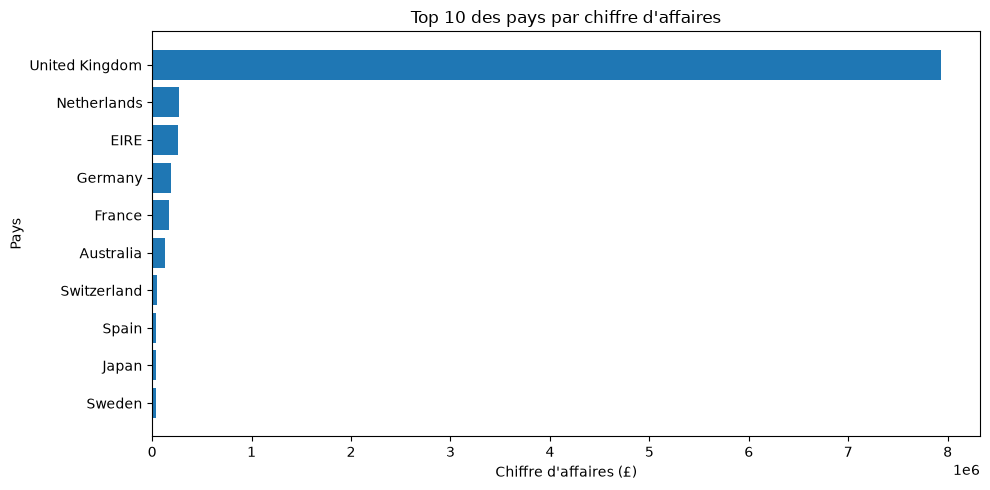

,StockCode,Description,chiffre_affaires,quantite_vendue,nb_factures
1235,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988
2390,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
2468,47566,PARTY BUNTING,99445.23,18283,1685
1945,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
1867,23084,RABBIT NIGHT LIGHT,66870.03,30739,994
931,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160
2666,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455
2532,79321,CHILLI LIGHTS,54096.36,10302,661
1309,22502,PICNIC BASKET WICKER SMALL,51408.77,1937,463
1034,22197,SMALL POPCORN HOLDER,51334.47,56898,1392


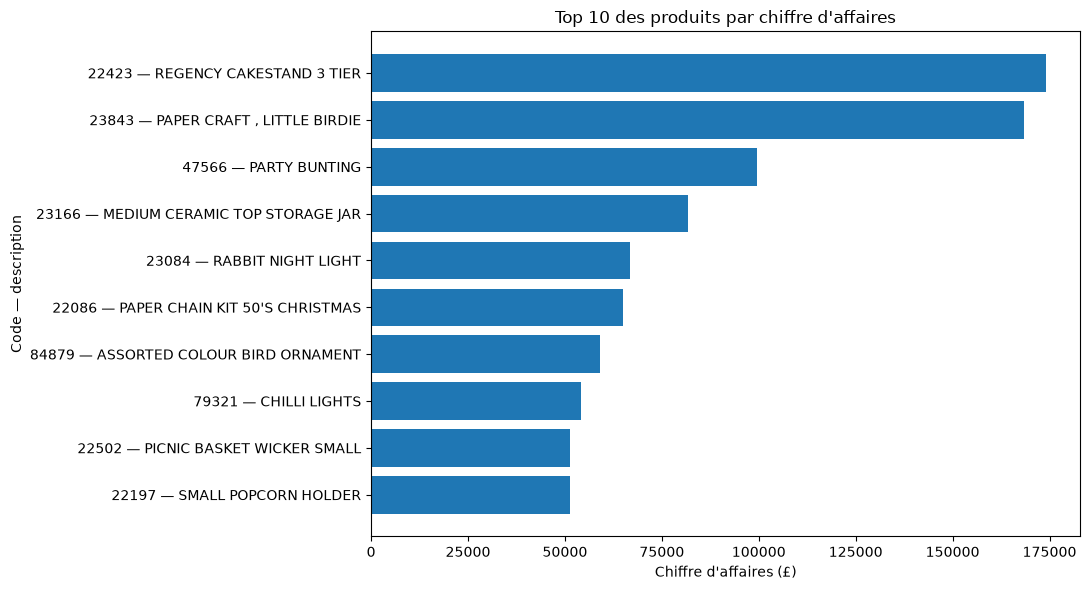

,mois,montant
0,2010-12,681867.68
1,2011-01,582246.11
2,2011-02,452685.03
3,2011-03,619860.72
4,2011-04,457415.58
5,2011-05,669162.07
6,2011-06,678033.73
7,2011-07,616710.93
8,2011-08,659840.75
9,2011-09,957036.68


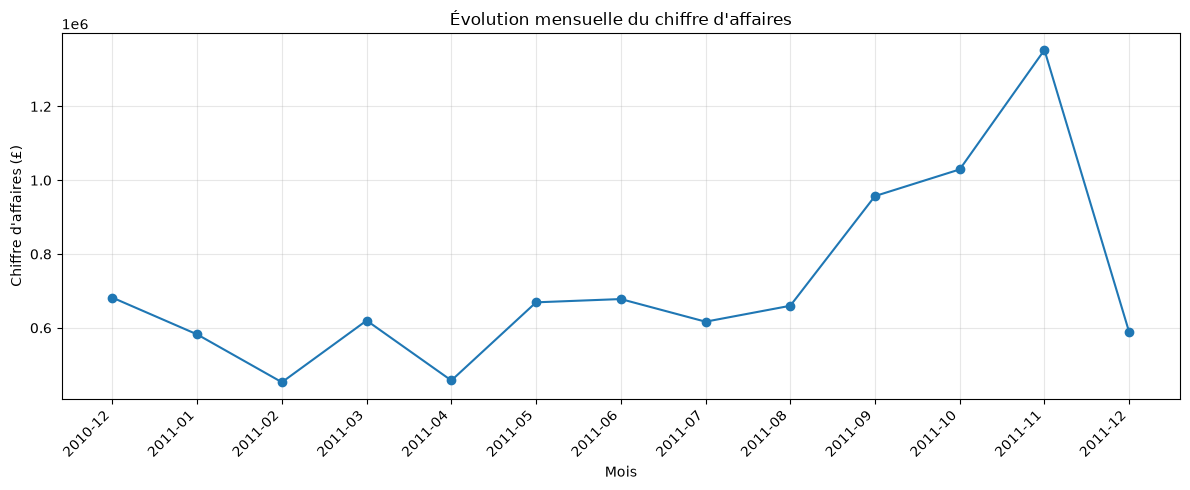

In [29]:
import matplotlib.pyplot as plt

# Chiffre d'affaires par pays
ca_pays = (
    ventes.groupby("Country", as_index=False)["montant"]
    .sum()
    .sort_values("montant", ascending=False)
)

display(ca_pays.head(10))

# Graphique : top 10 pays
top_pays = ca_pays.head(10).sort_values("montant")
plt.figure(figsize=(10, 5))
plt.barh(top_pays["Country"], top_pays["montant"])
plt.title("Top 10 des pays par chiffre d'affaires")
plt.xlabel("Chiffre d'affaires (£)")
plt.ylabel("Pays")
plt.tight_layout()
plt.show()

# Chiffre d'affaires par produit
ca_produits = (
    ventes.groupby("StockCode", as_index=False)
    .agg(
        Description=("Description", "first"),
        chiffre_affaires=("montant", "sum"),
        quantite_vendue=("Quantity", "sum"),
        nb_factures=("InvoiceNo", "nunique")
    )
    .sort_values("chiffre_affaires", ascending=False)
)

display(ca_produits.head(10))

# Graphique : top 10 produits
top_produits = ca_produits.head(10).sort_values("chiffre_affaires")
plt.figure(figsize=(11, 6))
plt.barh(
    top_produits["StockCode"] + " — " + top_produits["Description"].fillna(""),
    top_produits["chiffre_affaires"]
)
plt.title("Top 10 des produits par chiffre d'affaires")
plt.xlabel("Chiffre d'affaires (£)")
plt.ylabel("Code — description")
plt.tight_layout()
plt.show()

# Chiffre d'affaires mensuel
ventes["mois"] = ventes["InvoiceDate"].dt.to_period("M")
ca_mensuel = (
    ventes.dropna(subset=["InvoiceDate"])
    .groupby("mois", as_index=False)["montant"]
    .sum()
)
ca_mensuel["mois"] = ca_mensuel["mois"].astype(str)

display(ca_mensuel)

plt.figure(figsize=(12, 5))
plt.plot(ca_mensuel["mois"], ca_mensuel["montant"], marker="o")
plt.title("Évolution mensuelle du chiffre d'affaires")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires (£)")
plt.xticks(rotation=45, ha="right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Commentaire à rédiger après exécution :** identifier le pays numéro 1, le produit numéro 1 et les mois les plus forts/faibles. Le dataset s'arrête le 9 décembre 2011 : décembre 2011 est donc un mois incomplet et ne doit pas être comparé directement aux mois complets.


### Question 2 — Quel est le panier moyen et quelle part des factures est annulée ?

Les valeurs sont calculées dans le tableau `kpi_principaux`. Le panier moyen est basé sur les factures de vente distinctes. Le taux d'annulation utilise les numéros de factures distincts dans les ventes et les annulations.


In [30]:
print(f"Panier moyen : £{panier_moyen:,.2f}")
print(f"Factures de vente : {nb_factures_vente:,}")
print(f"Factures annulées : {nb_factures_annulees:,}")
print(f"Taux d'annulation : {taux_annulation:.2f} %")


Panier moyen : £478.06
Factures de vente : 19,549
Factures annulées : 3,836
Taux d'annulation : 16.40 %


### Question 3 — Quels clients rapportent le plus ?

On classe les clients identifiés selon leur chiffre d'affaires cumulé. Le client inconnu (`CustomerID = 0`) est exclu, car il ne permet pas d'identifier une personne ou une entreprise.


,CustomerID,chiffre_affaires,nb_factures,quantite_totale
1685,14646.0,265106.92,71,189631
4180,18102.0,253922.76,60,62811
3713,17450.0,180687.03,46,65779
2999,16446.0,168472.50,2,80997
1874,14911.0,125430.46,198,74163
55,12415.0,121265.99,20,75558
1329,14156.0,113029.11,52,55027
3756,17511.0,80952.39,30,59033
0,12346.0,77183.60,1,74215
2693,16029.0,65153.49,61,35867


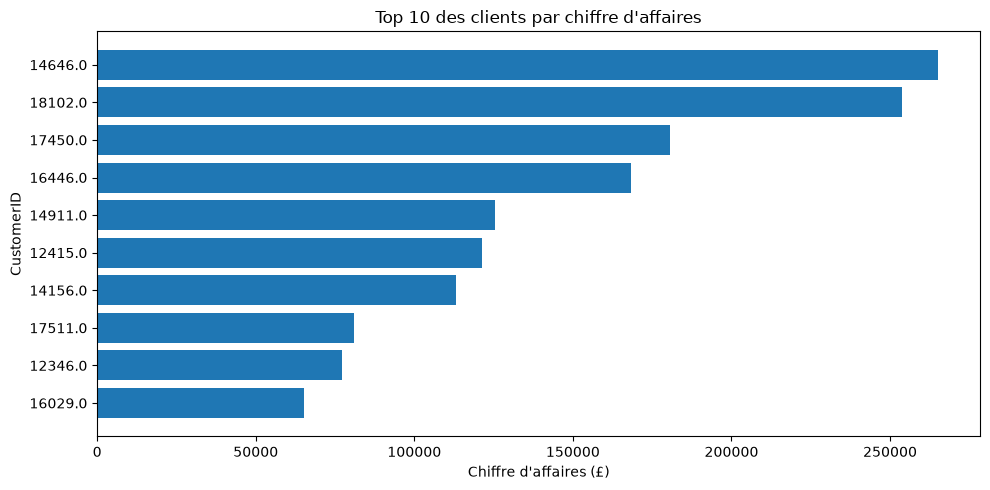

In [31]:
clients = (
    ventes[ventes["CustomerID"] != 0]
    .groupby("CustomerID", as_index=False)
    .agg(
        chiffre_affaires=("montant", "sum"),
        nb_factures=("InvoiceNo", "nunique"),
        quantite_totale=("Quantity", "sum")
    )
    .sort_values("chiffre_affaires", ascending=False)
)

top_clients = clients.head(10)
display(top_clients)

plt.figure(figsize=(10, 5))
top_clients_graph = top_clients.sort_values("chiffre_affaires")
plt.barh(
    top_clients_graph["CustomerID"].astype(str),
    top_clients_graph["chiffre_affaires"]
)
plt.title("Top 10 des clients par chiffre d'affaires")
plt.xlabel("Chiffre d'affaires (£)")
plt.ylabel("CustomerID")
plt.tight_layout()
plt.show()


### Question 4 — Quels produits faut-il mettre en avant ?

Une première approche consiste à repérer les produits qui combinent chiffre d'affaires élevé, quantité vendue importante et présence sur plusieurs factures. Il s'agit d'une recommandation exploratoire, pas d'une preuve de rentabilité : le dataset ne contient pas le coût d'achat ni la marge.

**Attention aux valeurs extrêmes :** inspecter les produits qui ont un chiffre d'affaires très élevé mais proviennent d'une quantité exceptionnelle ou d'un très petit nombre de factures avant de les recommander.


,StockCode,Description,chiffre_affaires,quantite_vendue,nb_factures,part_du_ca_pct
1235,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988,1.86
2390,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,1.80
2468,47566,PARTY BUNTING,99445.23,18283,1685,1.06
1945,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247,0.87
1867,23084,RABBIT NIGHT LIGHT,66870.03,30739,994,0.72
931,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160,0.69
2666,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455,0.63
2532,79321,CHILLI LIGHTS,54096.36,10302,661,0.58
1309,22502,PICNIC BASKET WICKER SMALL,51408.77,1937,463,0.55
1034,22197,SMALL POPCORN HOLDER,51334.47,56898,1392,0.55


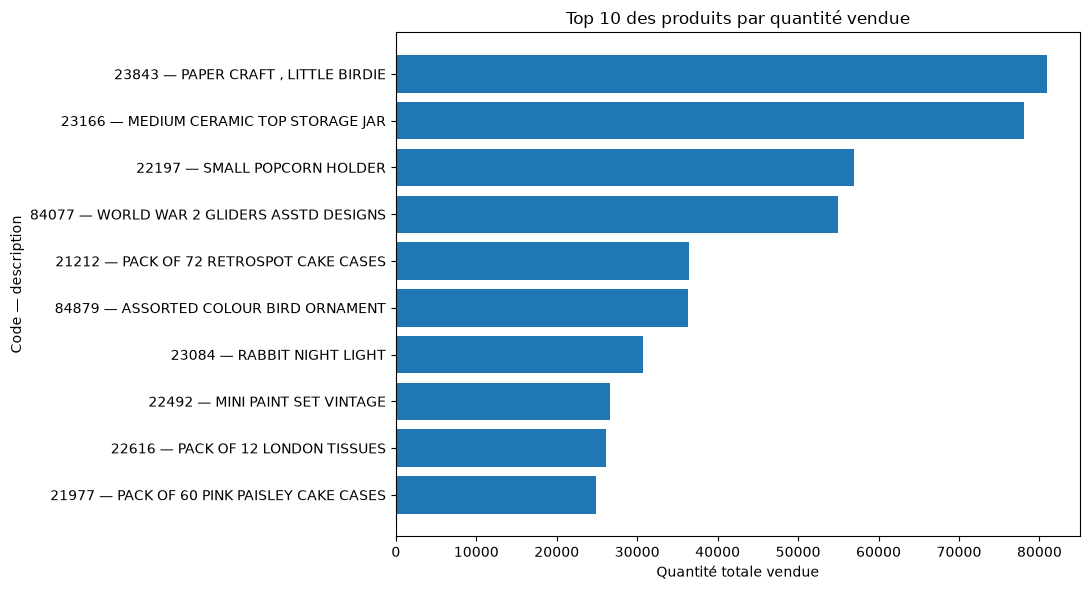

,StockCode,Description,chiffre_affaires,quantite_vendue,nb_factures,part_du_ca_pct
2390,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,1.80
719,21769,VINTAGE POST OFFICE CABINET,607.65,11,2,0.01
1101,22275,WEEKEND BAG VINTAGE ROSE PAISLEY,527.85,69,1,0.01
2555,82615,PINK MARSHMALLOW SCARF KNITTING KIT,91.80,36,1,0.00
870,22016,DOTCOMGIFTSHOP GIFT VOUCHER £100.00,83.33,1,1,0.00
986,22145,CHRISTMAS CRAFT HEART STOCKING,63.00,30,1,0.00
637,21655,HANGING RIDGE GLASS T-LIGHT HOLDER,60.84,36,2,0.00
2622,84679,CLASSICAL ROSE TABLE LAMP,55.70,6,2,0.00
2593,84539,KNITTED RABBIT DOLL,42.90,26,2,0.00
2722,85092,CANDY SPOT TEA COSY,40.05,27,2,0.00


In [32]:
# Tableau comparatif : CA, quantité vendue et nombre de factures
produits_a_evaluer = ca_produits.copy()
produits_a_evaluer["part_du_ca_pct"] = (
    100 * produits_a_evaluer["chiffre_affaires"] / ca_total
).round(2)

display(produits_a_evaluer.head(20))

# Produits souvent achetés : top 10 par quantité
top_quantites = (
    produits_a_evaluer.sort_values("quantite_vendue", ascending=False)
    .head(10)
    .sort_values("quantite_vendue")
)

plt.figure(figsize=(11, 6))
plt.barh(
    top_quantites["StockCode"] + " — " + top_quantites["Description"].fillna(""),
    top_quantites["quantite_vendue"]
)
plt.title("Top 10 des produits par quantité vendue")
plt.xlabel("Quantité totale vendue")
plt.ylabel("Code — description")
plt.tight_layout()
plt.show()

# Repérer les produits qui pèsent beaucoup en CA mais apparaissent sur peu de factures
display(
    produits_a_evaluer[
        produits_a_evaluer["nb_factures"] <= 2
    ].sort_values("chiffre_affaires", ascending=False).head(10)
)


2éme partie 

In [1]:
import sqlite3  #permet de créer et de manipuler une base SQLite.
import pandas as pd

In [2]:
ventes = pd.read_csv("../data/clean/ventes.csv")

ventes.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,montant
0,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
1,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom,15.30
2,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom,25.50
3,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom,11.10
4,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom,11.10


In [3]:
#Créer la connexion à la base SQLite
con = sqlite3.connect("../data/retail.db")

In [4]:
#Vérifier la connexion
print(con)

In [5]:
#Enregistrer les données dans la base SQLite
ventes.to_sql(
    "ventes",
    con,
    if_exists="replace",
    #index=False	Ne sauvegarde pas l'index Pandas comme une colonne SQL
    index=False
)

472253

In [6]:
#Vérifier le nombre de lignes dans la table "ventes"
pd.read_sql(
    "SELECT COUNT(*) AS nombre_lignes FROM ventes",
    con
)

,nombre_lignes
0,472253


In [8]:
with open("../sql/01_verification.sql", "r", encoding="utf-8") as f:
    requete = f.read()

pd.read_sql_query(requete, con)

,COUNT(*)
0,472253


## 2.2 — Analyse SQL
### 1. Calcul du chiffre d'affaires total

In [9]:
requete = """
SELECT ROUND(SUM(montant), 2) AS chiffre_affaires
FROM ventes;
"""

pd.read_sql_query(requete, con)

,chiffre_affaires
0,9345497.67


In [ ]:
## 2.3 — CTE et fonctions de fenêtrage
### Exercice 1 — Analyse mensuelle du chiffre d'affaires
requete = """
WITH ventes_mensuelles AS (
    SELECT
        strftime('%Y-%m', InvoiceDate) AS mois,
        SUM(montant) AS chiffre_affaires
    FROM ventes
    GROUP BY strftime('%Y-%m', InvoiceDate)
)

SELECT *
FROM ventes_mensuelles
ORDER BY mois;
"""
#WITH ventes_mensuelles AS : crée une CTE.
#strftime('%Y-%m', InvoiceDate) : extrait l'année et le mois.

pd.read_sql_query(requete, con)

,mois,chiffre_affaires
0,2010-12,681867.68
1,2011-01,582246.11
2,2011-02,452685.03
3,2011-03,619860.72
4,2011-04,457415.58
5,2011-05,669162.07
6,2011-06,678033.73
7,2011-07,616710.93
8,2011-08,659840.75
9,2011-09,957036.68


In [11]:
requete = """
WITH ventes_mensuelles AS (
    SELECT '2025-01' AS mois, 5000 AS ca
    UNION ALL
    SELECT '2025-02', 8000
    UNION ALL
    SELECT '2025-03', 6000
    UNION ALL
    SELECT '2025-04', 10000
)

SELECT
    mois,
    ca,

    LAG(ca) OVER (ORDER BY mois) AS ca_precedent,

    LEAD(ca) OVER (ORDER BY mois) AS ca_suivant,

    SUM(ca) OVER (ORDER BY mois) AS ca_cumule,

    ROUND(
        AVG(ca) OVER (
            ORDER BY mois
            ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
        ), 2
    ) AS moyenne_mobile

FROM ventes_mensuelles;
"""

pd.read_sql_query(requete, con)

,mois,ca,ca_precedent,ca_suivant,ca_cumule,moyenne_mobile
0,2025-01,5000,NaN,8000.0,5000,5000.00
1,2025-02,8000,5000.0,6000.0,13000,6500.00
2,2025-03,6000,8000.0,10000.0,19000,6333.33
3,2025-04,10000,6000.0,NaN,29000,8000.00
